In [1]:
!unzip -q /content/unet2.zip -d /content/unet2_dataset
import os

for root, dirs, files in os.walk("/content/unet2_dataset"):
    print(root)
    if len(files) > 0:
        print("Files:", files[:3])

/content/unet2_dataset
/content/unet2_dataset/Annotator 1 (biologist)
/content/unet2_dataset/Annotator 1 (biologist)/overlay_save_path
Files: ['Human_ThyroidGland_02.tif', 'Human_ThyroidGland_03.tif', 'Human_Thymus_02.tif']
/content/unet2_dataset/Annotator 1 (biologist)/mask binary without border erode
Files: ['Human_LymphNodes_03.png', 'Human_Pancreas_01.png', 'Human_Mediastinum_03.png']
/content/unet2_dataset/Annotator 1 (biologist)/weighted_maps_erode
Files: ['Human_LymphNodes_03.png', 'Human_Pancreas_01.png', 'Human_Mediastinum_03.png']
/content/unet2_dataset/Annotator 1 (biologist)/label masks
Files: ['Human_ThyroidGland_02.tif', 'Human_ThyroidGland_03.tif', 'Human_Thymus_02.tif']
/content/unet2_dataset/Annotator 1 (biologist)/mask binary
Files: ['Human_LymphNodes_03.png', 'Human_Pancreas_01.png', 'Human_Mediastinum_03.png']
/content/unet2_dataset/Annotator 1 (biologist)/label masks modify
Files: ['Human_ThyroidGland_02.tif', 'Human_ThyroidGland_03.tif', 'Human_Thymus_02.tif']
/co

In [1]:
# ============================================================
# FINAL PART 1 : U-NET++ FOR CRYONUSEG
# ============================================================

!pip install albumentations==1.4.3 --quiet

# ============================================================
# IMPORTS
# ============================================================

import os
import glob
import cv2
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from tqdm import tqdm
from sklearn.model_selection import KFold

import torch
import torch.nn as nn
import torch.optim as optim

from torch.utils.data import Dataset, DataLoader

import albumentations as A
from albumentations.pytorch import ToTensorV2

# ============================================================
# REPRODUCIBILITY
# ============================================================

SEED = 42

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)

# ============================================================
# DEVICE
# ============================================================

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("Using device:", DEVICE)

# ============================================================
# DATA PATHS
# ============================================================

IMAGE_DIR = "/content/unet2_dataset/tissue images"
MASK_DIR  = "/content/unet2_dataset/Annotator 1 (biologist)/mask binary"

# ============================================================
# HYPERPARAMETERS
# ============================================================

IMG_SIZE = 256
BATCH_SIZE = 4
EPOCHS = 22
LR = 1e-4
NUM_FOLDS = 3

# ============================================================
# LOAD FILES
# ============================================================

image_paths = sorted(glob.glob(os.path.join(IMAGE_DIR, "*.tif")))
mask_paths  = sorted(glob.glob(os.path.join(MASK_DIR, "*.png")))

print("Images:", len(image_paths))
print("Masks :", len(mask_paths))

assert len(image_paths) == len(mask_paths), "Mismatch between images and masks!"

# ============================================================
# AUGMENTATIONS
# ============================================================

train_transform = A.Compose([
    A.Resize(IMG_SIZE, IMG_SIZE),

    A.HorizontalFlip(p=0.5),
    A.VerticalFlip(p=0.5),
    A.RandomRotate90(p=0.5),

    A.Rotate(limit=10, p=0.3),

    A.Normalize(
        mean=(0.485, 0.456, 0.406),
        std=(0.229, 0.224, 0.225)
    ),

    ToTensorV2()
])

val_transform = A.Compose([
    A.Resize(IMG_SIZE, IMG_SIZE),

    A.Normalize(
        mean=(0.485, 0.456, 0.406),
        std=(0.229, 0.224, 0.225)
    ),

    ToTensorV2()
])

# ============================================================
# DATASET CLASS
# ============================================================

class CryoNuSegDataset(Dataset):
    def __init__(self, image_paths, mask_paths, transform=None):
        self.image_paths = image_paths
        self.mask_paths = mask_paths
        self.transform = transform

    def __len__(self):
        return len(self.image_paths)

    def __getitem__(self, idx):

        image = cv2.imread(self.image_paths[idx])
        image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

        mask = cv2.imread(self.mask_paths[idx], cv2.IMREAD_GRAYSCALE)

        mask = (mask > 127).astype(np.float32)

        if self.transform:
            augmented = self.transform(
                image=image,
                mask=mask
            )
            image = augmented["image"]
            mask = augmented["mask"]

        mask = mask.unsqueeze(0)

        return image, mask

# ============================================================
# METRICS
# ============================================================

def dice_score(preds, targets, smooth=1e-6):

    preds = torch.sigmoid(preds)
    preds = (preds > 0.5).float()

    intersection = (preds * targets).sum(dim=(1,2,3))
    union = preds.sum(dim=(1,2,3)) + targets.sum(dim=(1,2,3))

    dice = (2.0 * intersection + smooth) / (union + smooth)

    return dice.mean().item()


def iou_score(preds, targets, smooth=1e-6):

    preds = torch.sigmoid(preds)
    preds = (preds > 0.5).float()

    intersection = (preds * targets).sum(dim=(1,2,3))
    union = preds.sum(dim=(1,2,3)) + targets.sum(dim=(1,2,3)) - intersection

    iou = (intersection + smooth) / (union + smooth)

    return iou.mean().item()

# ============================================================
# LOSS FUNCTION
# ============================================================

class BCEDiceLoss(nn.Module):
    def __init__(self):
        super().__init__()

        self.bce = nn.BCEWithLogitsLoss()

    def forward(self, preds, targets):

        bce = self.bce(preds, targets)

        preds = torch.sigmoid(preds)

        intersection = (preds * targets).sum()

        dice = (2.0 * intersection + 1e-6) / (
            preds.sum() + targets.sum() + 1e-6
        )

        dice_loss = 1 - dice

        return bce + dice_loss

# ============================================================
# CONV BLOCK
# ============================================================

class ConvBlock(nn.Module):
    def __init__(self, in_channels, out_channels):
        super().__init__()

        self.block = nn.Sequential(
            nn.Conv2d(
                in_channels,
                out_channels,
                kernel_size=3,
                padding=1
            ),
            nn.BatchNorm2d(out_channels),
            nn.ReLU(inplace=True),

            nn.Conv2d(
                out_channels,
                out_channels,
                kernel_size=3,
                padding=1
            ),
            nn.BatchNorm2d(out_channels),
            nn.ReLU(inplace=True)
        )

    def forward(self, x):
        return self.block(x)

# ============================================================
# U-NET++
# ============================================================

class UNetPlusPlus(nn.Module):
    def __init__(self, in_channels=3, out_channels=1, base=16):
        super().__init__()

        filters = [
            base,
            base * 2,
            base * 4,
            base * 8,
            base * 16
        ]

        self.pool = nn.MaxPool2d(2)

        self.up = nn.Upsample(
            scale_factor=2,
            mode='bilinear',
            align_corners=True
        )

        # Encoder
        self.conv0_0 = ConvBlock(in_channels, filters[0])
        self.conv1_0 = ConvBlock(filters[0], filters[1])
        self.conv2_0 = ConvBlock(filters[1], filters[2])
        self.conv3_0 = ConvBlock(filters[2], filters[3])
        self.conv4_0 = ConvBlock(filters[3], filters[4])

        # Decoder
        self.conv0_1 = ConvBlock(filters[0] + filters[1], filters[0])
        self.conv1_1 = ConvBlock(filters[1] + filters[2], filters[1])
        self.conv2_1 = ConvBlock(filters[2] + filters[3], filters[2])
        self.conv3_1 = ConvBlock(filters[3] + filters[4], filters[3])

        self.conv0_2 = ConvBlock(filters[0]*2 + filters[1], filters[0])
        self.conv1_2 = ConvBlock(filters[1]*2 + filters[2], filters[1])
        self.conv2_2 = ConvBlock(filters[2]*2 + filters[3], filters[2])

        self.conv0_3 = ConvBlock(filters[0]*3 + filters[1], filters[0])
        self.conv1_3 = ConvBlock(filters[1]*3 + filters[2], filters[1])

        self.conv0_4 = ConvBlock(filters[0]*4 + filters[1], filters[0])

        self.final = nn.Conv2d(
            filters[0],
            out_channels,
            kernel_size=1
        )

    def forward(self, x):

        x0_0 = self.conv0_0(x)
        x1_0 = self.conv1_0(self.pool(x0_0))
        x2_0 = self.conv2_0(self.pool(x1_0))
        x3_0 = self.conv3_0(self.pool(x2_0))
        x4_0 = self.conv4_0(self.pool(x3_0))

        x3_1 = self.conv3_1(
            torch.cat([x3_0, self.up(x4_0)], dim=1)
        )

        x2_1 = self.conv2_1(
            torch.cat([x2_0, self.up(x3_0)], dim=1)
        )

        x1_1 = self.conv1_1(
            torch.cat([x1_0, self.up(x2_0)], dim=1)
        )

        x0_1 = self.conv0_1(
            torch.cat([x0_0, self.up(x1_0)], dim=1)
        )

        x2_2 = self.conv2_2(
            torch.cat([x2_0, x2_1, self.up(x3_1)], dim=1)
        )

        x1_2 = self.conv1_2(
            torch.cat([x1_0, x1_1, self.up(x2_1)], dim=1)
        )

        x0_2 = self.conv0_2(
            torch.cat([x0_0, x0_1, self.up(x1_1)], dim=1)
        )

        x1_3 = self.conv1_3(
            torch.cat([x1_0, x1_1, x1_2, self.up(x2_2)], dim=1)
        )

        x0_3 = self.conv0_3(
            torch.cat([x0_0, x0_1, x0_2, self.up(x1_2)], dim=1)
        )

        x0_4 = self.conv0_4(
            torch.cat([
                x0_0,
                x0_1,
                x0_2,
                x0_3,
                self.up(x1_3)
            ], dim=1)
        )

        return self.final(x0_4)

# ============================================================
# TEST MODEL
# ============================================================

model = UNetPlusPlus().to(DEVICE)

dummy = torch.randn(1, 3, IMG_SIZE, IMG_SIZE).to(DEVICE)

output = model(dummy)

print("Model Output Shape:", output.shape)

Using device: cpu
Images: 30
Masks : 30
Model Output Shape: torch.Size([1, 1, 256, 256])



FOLD 1/3

Epoch 1/22


Training:   0%|          | 0/5 [00:00<?, ?it/s]/usr/local/lib/python3.12/dist-packages/torch/utils/data/dataloader.py:1118: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  super().__init__(loader)


Train Loss : 1.2811
Val Loss   : 1.3587
Val Dice   : 0.0015
Val IoU    : 0.0008
Best model saved.

Epoch 2/22


Train Loss : 1.1646
Val Loss   : 1.3543
Val Dice   : 0.5052
Val IoU    : 0.3513
Best model saved.

Epoch 3/22


Train Loss : 1.1133
Val Loss   : 1.3335
Val Dice   : 0.5195
Val IoU    : 0.3666
Best model saved.

Epoch 4/22


...

Train Loss : 0.9878
Val Loss   : 1.0063
Val Dice   : 0.6739
Val IoU    : 0.5229

Epoch 19/22


Train Loss : 0.9722
Val Loss   : 1.0078
Val Dice   : 0.6698
Val IoU    : 0.5180

Epoch 20/22


Train Loss : 0.9696
Val Loss   : 1.0039
Val Dice   : 0.6639
Val IoU    : 0.5111

Epoch 21/22


Train Loss : 0.9572
Val Loss   : 1.0016
Val Dice   : 0.6673
Val IoU    : 0.5146

Epoch 22/22


Train Loss : 0.9586
Val Loss   : 0.9974
Val Dice   : 0.6775
Val IoU    : 0.5245


FOLD-WISE RESULTS
   Fold      Dice       IoU
0     1  0.739257  0.594498
1     2  0.775471  0.639334
2     3  0.692377  0.541240


FINAL AVERAGE RESULTS
Average Dice Score : 0.7357
Average IoU Score  : 0.5917


COMPARISON TABLE
     Model      Dice       IoU
0  U-Net++  0.735702  0.591691

Generating sample prediction...


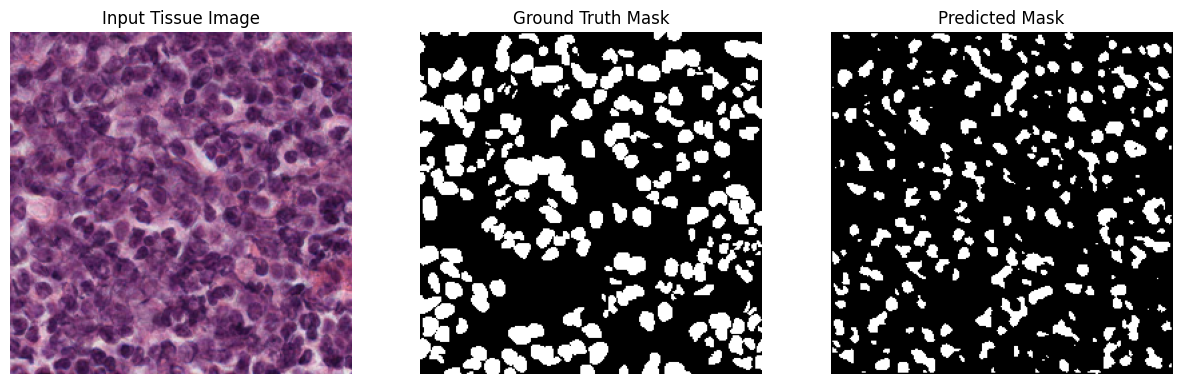

In [2]:
# ============================================================
# FINAL PART 2 : TRAINING + EVALUATION + FINAL RESULTS
# ============================================================

criterion = BCEDiceLoss()

# ============================================================
# TRAIN FUNCTION
# ============================================================

def train_one_epoch(model, loader, optimizer):
    model.train()

    running_loss = 0

    progress = tqdm(loader, desc="Training", leave=False)

    for images, masks in progress:

        images = images.to(DEVICE)
        masks = masks.to(DEVICE)

        optimizer.zero_grad()

        outputs = model(images)

        loss = criterion(outputs, masks)

        loss.backward()
        optimizer.step()

        running_loss += loss.item()

        progress.set_postfix(loss=loss.item())

    return running_loss / len(loader)

# ============================================================
# VALIDATION FUNCTION
# ============================================================

def validate(model, loader):
    model.eval()

    val_loss = 0
    total_dice = 0
    total_iou = 0

    with torch.no_grad():

        progress = tqdm(loader, desc="Validation", leave=False)

        for images, masks in progress:

            images = images.to(DEVICE)
            masks = masks.to(DEVICE)

            outputs = model(images)

            loss = criterion(outputs, masks)

            val_loss += loss.item()

            total_dice += dice_score(outputs, masks)
            total_iou += iou_score(outputs, masks)

    avg_loss = val_loss / len(loader)
    avg_dice = total_dice / len(loader)
    avg_iou = total_iou / len(loader)

    return avg_loss, avg_dice, avg_iou

# ============================================================
# 3-FOLD CROSS VALIDATION
# ============================================================

kf = KFold(
    n_splits=NUM_FOLDS,
    shuffle=True,
    random_state=SEED
)

fold_results = []

for fold, (train_idx, val_idx) in enumerate(kf.split(image_paths)):

    print("\n" + "="*60)
    print(f"FOLD {fold+1}/{NUM_FOLDS}")
    print("="*60)

    train_images = [image_paths[i] for i in train_idx]
    train_masks  = [mask_paths[i] for i in train_idx]

    val_images = [image_paths[i] for i in val_idx]
    val_masks  = [mask_paths[i] for i in val_idx]

    train_dataset = CryoNuSegDataset(
        train_images,
        train_masks,
        transform=train_transform
    )

    val_dataset = CryoNuSegDataset(
        val_images,
        val_masks,
        transform=val_transform
    )

    train_loader = DataLoader(
        train_dataset,
        batch_size=BATCH_SIZE,
        shuffle=True,
        num_workers=2,
        pin_memory=True
    )

    val_loader = DataLoader(
        val_dataset,
        batch_size=BATCH_SIZE,
        shuffle=False,
        num_workers=2,
        pin_memory=True
    )

    model = UNetPlusPlus().to(DEVICE)

    optimizer = optim.Adam(
        model.parameters(),
        lr=LR
    )

    scheduler = optim.lr_scheduler.ReduceLROnPlateau(
        optimizer,
        mode='max',
        factor=0.5,
        patience=3
    )

    best_dice = 0
    best_iou = 0

    for epoch in range(EPOCHS):

        print(f"\nEpoch {epoch+1}/{EPOCHS}")

        train_loss = train_one_epoch(
            model,
            train_loader,
            optimizer
        )

        val_loss, val_dice, val_iou = validate(
            model,
            val_loader
        )

        scheduler.step(val_dice)

        print(f"Train Loss : {train_loss:.4f}")
        print(f"Val Loss   : {val_loss:.4f}")
        print(f"Val Dice   : {val_dice:.4f}")
        print(f"Val IoU    : {val_iou:.4f}")

        if val_dice > best_dice:
            best_dice = val_dice
            best_iou = val_iou

            torch.save(
                model.state_dict(),
                f"/content/best_unetpp_fold_{fold+1}.pth"
            )

            print("Best model saved.")

    fold_results.append({
        "Fold": fold + 1,
        "Dice": best_dice,
        "IoU": best_iou
    })

# ============================================================
# FINAL RESULTS TABLE
# ============================================================

results_df = pd.DataFrame(fold_results)

print("\n")
print("="*60)
print("FOLD-WISE RESULTS")
print("="*60)
print(results_df)

avg_dice = results_df["Dice"].mean()
avg_iou = results_df["IoU"].mean()

print("\n")
print("="*60)
print("FINAL AVERAGE RESULTS")
print("="*60)
print(f"Average Dice Score : {avg_dice:.4f}")
print(f"Average IoU Score  : {avg_iou:.4f}")

comparison = pd.DataFrame({
    "Model": ["U-Net++"],
    "Dice": [avg_dice],
    "IoU": [avg_iou]
})

print("\n")
print("="*60)
print("COMPARISON TABLE")
print("="*60)
print(comparison)

# ============================================================
# SAMPLE VISUALIZATION
# ============================================================

print("\nGenerating sample prediction...")

sample_dataset = CryoNuSegDataset(
    val_images,
    val_masks,
    transform=val_transform
)

sample_image, sample_mask = sample_dataset[0]

model.eval()

with torch.no_grad():
    pred = model(
        sample_image.unsqueeze(0).to(DEVICE)
    )

    pred = torch.sigmoid(pred)
    pred = (pred > 0.5).float()

sample_image_np = sample_image.cpu().permute(1,2,0).numpy()
sample_mask_np = sample_mask.squeeze().cpu().numpy()
pred_np = pred.squeeze().cpu().numpy()

sample_image_np = (
    sample_image_np * np.array([0.229, 0.224, 0.225])
    + np.array([0.485, 0.456, 0.406])
)

sample_image_np = np.clip(sample_image_np, 0, 1)

plt.figure(figsize=(15,5))

plt.subplot(1,3,1)
plt.imshow(sample_image_np)
plt.title("Input Tissue Image")
plt.axis("off")

plt.subplot(1,3,2)
plt.imshow(sample_mask_np, cmap='gray')
plt.title("Ground Truth Mask")
plt.axis("off")

plt.subplot(1,3,3)
plt.imshow(pred_np, cmap='gray')
plt.title("Predicted Mask")
plt.axis("off")

plt.show()